# Sri Lanka Bird Biodiversity: Ensemble Learning Dashboard
### Predicting recorded bird species richness with Bagging, Boosting, Stacking and Hybrid models

**Student:** Indrajith KTN 224078X
**Module / Assignment:** Ensemble Learning Dashboard
**Date:** November 2026

> **AI use declaration:** The Python code in this project (the three notebooks and the Streamlit
> dashboard `app.py`) was **generated with the help of Claude (Anthropic)**. I ran the code, checked the
> outputs, and wrote the interpretation of the results myself.

**Project files**
| File | Purpose |
|---|---|
| `notebooks/step1_models.ipynb` | Bagging, Boosting, Stacking, RF + ANN hybrid, model comparison |
| `notebooks/step2_timeseries.ipynb` | ARIMA, SARIMA, lag-XGBoost, RF + ARIMA hybrid |
| `notebooks/step3_explainability.ipynb` | Feature importance, permutation importance, SHAP |
| `notebooks/step4_report.ipynb` | This report (problem, results, research discussion, conclusion) |
| `app.py` | Streamlit dashboard (loads the saved models from `models/`) |

## 1. Problem and innovation

**Problem.** Sri Lanka is a biodiversity hotspot, but bird records come from many observers and
are not evenly spread. Conservation and eco-tourism planners need to know *where and when* many bird
species are likely to be recorded, and which environmental factors are linked to it.

**Innovation.** This project joins a large Sri Lankan bird-record dataset with local environmental data
(climate, vegetation, elevation, population, night light) and turns it into an interactive
**Bird Watching Hotspot Planner**. A user chooses a district and month and gets a predicted number of
recorded species, together with an explanation of the factors behind it. The project also tests
**hybrid models** (RF + ANN for tabular data, RF + ARIMA for the monthly time series) and uses
**Sri Lankan monsoon seasons** (North-East, South-West, two inter-monsoons) instead of
foreign four-season calendars.

**Target variable:** `species_richness` = number of different bird species recorded in a district in a month.

## 2. Data source and preparation

- **Raw data:** `SriLanka-Bird-Diversity-Dataset.csv`, about 1.55 million bird occurrence records for Sri Lanka
  (species name, district `stateProvince`, location, date, individual count) with matching environmental columns
  (temperature, rainfall, humidity, wind, NDVI, elevation, night light, population layer, aerosol and land-cover fields).
- **Source:** `[WRITE HERE: where you downloaded the dataset, with the link, e.g. Kaggle / GBIF page]`
- **Processed data:** records were aggregated by **district x year x month**, giving
  **2,454 rows**, **25 districts**, **2014-2024** (`data/processed/bird_monthly_data.csv`).
- **Features used:** district, monsoon season, year, month, temperature, rainfall, humidity, NDVI, wind,
  elevation, population density, night light. Categorical columns were one-hot encoded.
- **Split (time-based, no shuffling):** train = 2014-2022 (1,915 rows), test = 2023-2024 (539 rows).
- **Why a time split?** Predicting the future from the past is the real use case, and shuffling would leak future
  information into training.
- **Tuning:** `RandomizedSearchCV` with `TimeSeriesSplit` for Random Forest, XGBoost and LightGBM; `random_state=42` everywhere.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

PROC = "../data/processed"
if not os.path.exists(PROC):
    PROC = "data/processed"

data = pd.read_csv(f"{PROC}/bird_monthly_data.csv")
print("Rows:", len(data), "| Districts:", data["stateProvince"].nunique(),
      "| Years:", data["Year"].min(), "-", data["Year"].max())
data[["species_richness", "observation_count"]].describe().round(1)

Rows: 2454 | Districts: 25 | Years: 2014 - 2024


,species_richness,observation_count
count,2454.0,2454.0
mean,75.8,632.5
std,49.5,1157.1
min,1.0,1.0
25%,33.0,44.0
50%,75.0,184.0
75%,112.0,674.0
max,226.0,9414.0


## 3. Tabular models: Bagging, Boosting, Stacking and the RF + ANN hybrid

| Type | Models |
|---|---|
| Baseline | Linear Regression |
| **Bagging** | Random Forest, Bagging (decision trees), ExtraTrees |
| **Boosting** | Gradient Boosting, XGBoost, LightGBM, CatBoost |
| **Stacking** | RF + XGBoost + LightGBM + CatBoost with a Ridge meta-model |
| **Hybrid (RF + ANN)** | ANN (MLP) alone; average of RF and ANN; stacking of RF and ANN with Ridge |

All models use the **same train/test split and the same metrics** (MAE, RMSE, R2, MAPE, training time).

Best model by MAE: Hybrid RF+ANN (average)


,Rank,Model,MAE,RMSE,R2,MAPE,Train_Time_s
0,1,Hybrid RF+ANN (average),25.431,33.272,0.495,90.617,9.31
1,2,Hybrid RF+ANN (stacking),26.210,34.575,0.454,92.276,6.69
2,3,CatBoost,26.442,33.595,0.485,78.695,1.39
3,4,Stacking (RF+XGB+LGBM+Cat),26.477,33.797,0.478,78.422,7.21
4,5,Linear Regression,26.689,35.158,0.436,99.107,0.09
5,6,XGBoost,26.709,34.010,0.472,78.824,2.83
6,7,LightGBM,28.022,35.057,0.439,79.811,2.13
7,8,ExtraTrees,28.462,36.468,0.393,79.461,0.42
8,9,ANN (MLP),29.041,38.001,0.341,105.134,0.90
9,10,Gradient Boosting,29.383,35.853,0.413,87.506,1.06


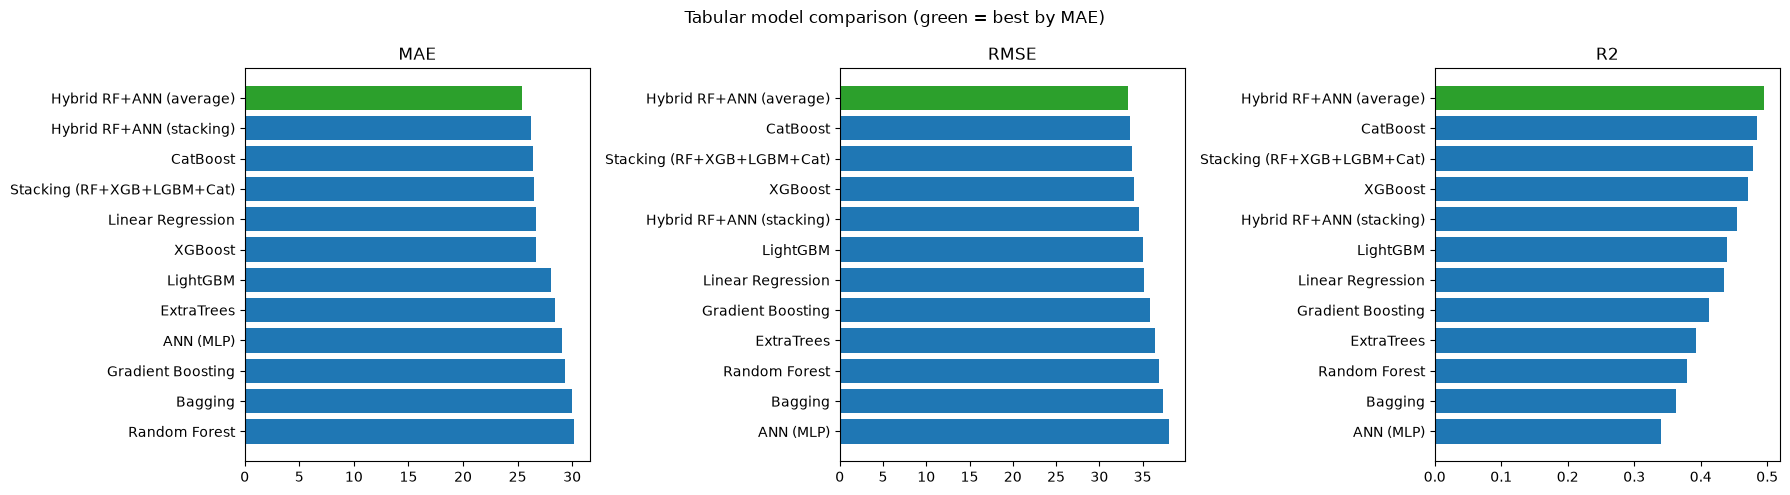

In [2]:
res = pd.read_csv(f"{PROC}/model_results.csv")
best = res.sort_values("MAE").iloc[0]["Model"]
print("Best model by MAE:", best)
display(res.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    order = res.sort_values(metric, ascending=(metric != "R2"))
    ax.barh(order["Model"], order[metric],
            color=["tab:green" if m == best else "tab:blue" for m in order["Model"]])
    ax.set_title(metric); ax.invert_yaxis()
plt.suptitle("Tabular model comparison (green = best by MAE)")
plt.tight_layout(); plt.show()

### 3.1 Interpretation of the tabular results

**Which model won?** The **Hybrid RF + ANN (average)** gave the best result on all three main metrics
(MAE 25.43, RMSE 33.27, R2 0.495). The next best group is very close: Hybrid RF + ANN (stacking) 26.21,
CatBoost 26.44, Stacking 26.48, Linear Regression 26.69 and XGBoost 26.71 (MAE).

**Why did the hybrid win?** Random Forest (trees) and the ANN (smooth neural network) make *different kinds
of mistakes*. Trees make step-like predictions, the ANN makes smooth ones. Averaging them cancels part of each
model's error. This is the same reason ensembles work in general: diverse models make less correlated errors.

**Why was Random Forest near the bottom?** Random Forest (MAE 30.13) and Bagging (MAE 29.99) were weaker than
the boosting models and even weaker than Linear Regression. The dataset is small (1,915 training rows) and noisy,
because richness depends strongly on how many observations were made. Bagging reduces variance but does not reduce
bias, and deep trees can learn the noise. Boosting builds shallow trees one after another and uses a learning rate,
which gives smoother and more regularised fits. CatBoost, with ordered boosting and symmetric trees, is known
to be strong on small, noisy data, which matches its good rank here.

**Why is Linear Regression so close?** The best model improved on the Linear baseline by only about 5% in MAE
(26.69 -> 25.43). The signal in the environmental features is weak and mostly additive, so complex models
have little extra structure to find. This is an honest finding: ensembles are not automatically much better.

**How reliable is the ranking?** The test set has 539 rows and one split was used. Differences of about one species
between the top models are small and may not be significant. The clear conclusions are: (1) boosting, stacking and
hybrids are better than plain bagging here; (2) all models struggle (R2 below 0.5).

**Note on MAPE.** MAPE is high (80-105%) because some district-months have very few species (as low as 1),
which inflates percentage errors. MAE is easier to read: the best model is wrong by about 25 species on average.

**Speed.** Random Forest took the longest to train in this run (8.4 s, including its random search), compared with
XGBoost 2.8 s, LightGBM 2.1 s and CatBoost 1.4 s. The tuned models (RF, XGBoost, LightGBM) include search time;
CatBoost used fixed settings.

## 4. Why is R2 only about 0.5? The effect of survey effort

Species richness is the number of species *recorded*. It depends on how many observations were made.
As a check, the same Random Forest was trained with and without `observation_count`:

| Features | MAE | R2 |
|---|---|---|
| Environment only | 30.90 | 0.331 |
| Environment + observation_count | 10.19 | 0.915 |

Survey effort explains most of the variation. So environmental models predict *recorded* richness, which mixes
real biodiversity with how much people watch birds. The main experiment deliberately **excludes** observation_count,
because the goal is to learn the effect of the environment and because effort is not known when planning ahead.

## 5. Time-series models: ARIMA, SARIMA and the RF + ARIMA hybrid

The district data was averaged into one monthly series for Sri Lanka (132 months, 2014-2024).
Train = 2014-2022, test = the last 24 months (2023-2024). Models: Seasonal Naive baseline, ARIMA and SARIMA
(orders chosen by AIC), Lag-feature XGBoost, **RF + ARIMA** and **RF + SARIMA** hybrids.

**Hybrid method:** ARIMA/SARIMA captures trend and seasonality. A Random Forest then learns the ARIMA residuals
(what ARIMA missed) from residual lags, month and climate. Final forecast = ARIMA forecast + RF residual forecast.

,Rank,Model,MAE,RMSE,MAPE,Train_Time_s
0,1,SARIMA,11.512,15.945,13.343,0.14
1,2,Hybrid RF + SARIMA,13.053,18.624,15.283,1.62
2,3,Hybrid RF + ARIMA,15.716,18.597,16.895,1.63
3,4,ARIMA,17.065,19.581,18.028,0.17
4,5,Seasonal Naive,17.236,23.589,20.493,0.00
5,6,Lag-feature XGBoost,18.696,22.056,20.721,0.29


ARIMA  -> RF+ARIMA : MAE 17.07 -> 15.72
SARIMA -> RF+SARIMA: MAE 11.51 -> 13.05


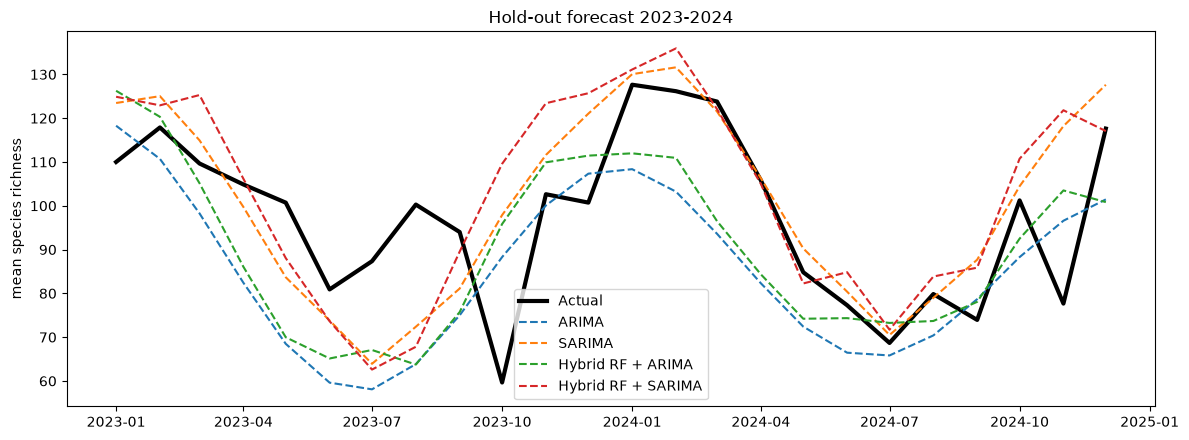

In [3]:
ts_res = pd.read_csv(f"{PROC}/timeseries_results.csv")
display(ts_res.round(3))
mae = ts_res.set_index("Model")["MAE"]
print(f"ARIMA  -> RF+ARIMA : MAE {mae['ARIMA']:.2f} -> {mae['Hybrid RF + ARIMA']:.2f}")
print(f"SARIMA -> RF+SARIMA: MAE {mae['SARIMA']:.2f} -> {mae['Hybrid RF + SARIMA']:.2f}")

fc = pd.read_csv(f"{PROC}/timeseries_forecasts.csv", parse_dates=["date"])
plt.figure(figsize=(12, 4.5))
plt.plot(fc["date"], fc["Actual"], color="black", linewidth=3, label="Actual")
for m in ["ARIMA", "SARIMA", "Hybrid RF + ARIMA", "Hybrid RF + SARIMA"]:
    plt.plot(fc["date"], fc[m], linestyle="--", label=m)
plt.title("Hold-out forecast 2023-2024"); plt.ylabel("mean species richness")
plt.legend(); plt.tight_layout(); plt.show()

### 5.1 Interpretation of the time-series results

- **SARIMA was best** (MAE 11.51, RMSE 15.95, MAPE 13.3%). The monthly bird records have a clear yearly cycle
  (high in the North-East monsoon / migratory season, low around the South-West monsoon), and SARIMA models
  this seasonality directly.
- **RF + ARIMA beat plain ARIMA** (MAE 17.07 -> 15.72). ARIMA without seasonal terms misses the yearly cycle, so
  its residuals still contain pattern. The Random Forest could learn part of this pattern from month and climate, so the hybrid helps.
- **RF + SARIMA was worse than SARIMA** (MAE 11.51 -> 13.05). SARIMA already captured most of the structure,
  so its residuals are close to noise. The Random Forest then learns noise and adds error. **A hybrid only helps
  when the base model leaves learnable structure in the residuals.**
- The plain Lag-feature XGBoost was the weakest (MAE 18.70). With only 108 training months and recursive
  multi-step forecasting, small errors accumulate.
- The test period is only 24 months, so these results should be treated as indicative.

## 6. Explainability

Built-in feature importance (Random Forest, XGBoost), permutation importance and SHAP were computed
(`step3_explainability.ipynb`).

,Feature,RandomForest,XGBoost,Permutation_MAE
0,District (location),0.217,0.575,10.470
1,Monsoon season,0.122,0.325,1.135
2,Year,0.139,0.027,0.000
3,Population density,0.088,0.013,3.218
4,Month,0.033,0.012,0.880
5,Rainfall,0.062,0.008,1.042
6,Temperature,0.071,0.008,0.905
7,Elevation,0.062,0.007,2.415
8,Night light,0.052,0.007,0.814
9,Wind,0.058,0.007,1.543


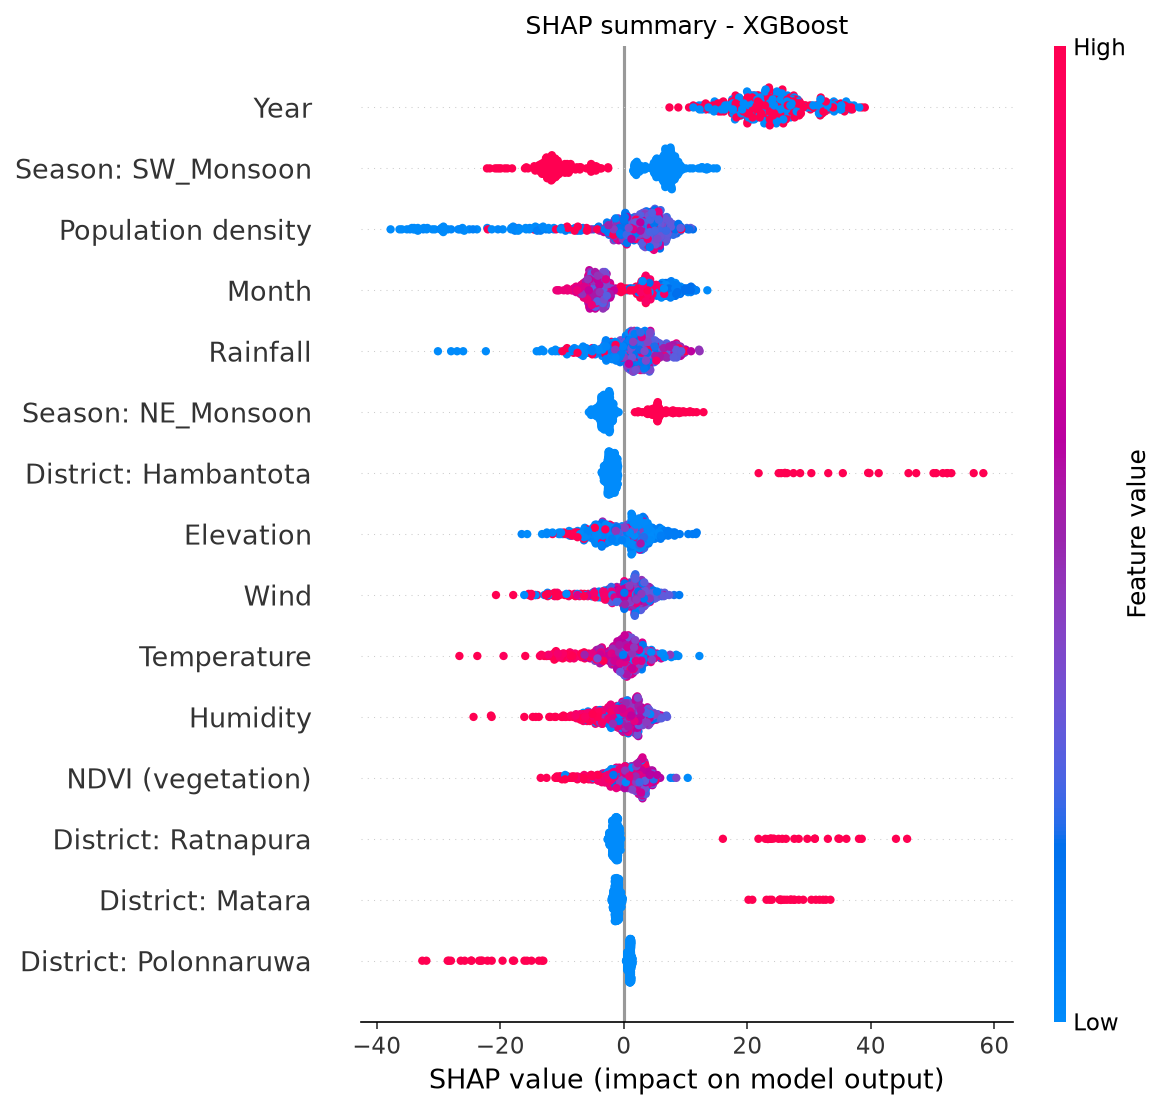

In [4]:
imp = pd.read_csv(f"{PROC}/feature_importance.csv")
display(imp.round(3))
if os.path.exists(f"{PROC}/shap_summary.png"):
    display(Image(filename=f"{PROC}/shap_summary.png", width=650))

### 6.1 Interpretation

- **District** is the strongest factor in both Random Forest and XGBoost, followed by **monsoon season**. Districts
  differ in habitat and in how often they are visited by birdwatchers. In the SHAP plot, Hambantota, Ratnapura and
  Matara push the prediction up strongly, and Polonnaruwa pushes it down.
- **Monsoon season:** the North-East monsoon (Dec-Feb) raises the prediction and the South-West monsoon (May-Sep)
  lowers it, consistent with the migratory bird season (Oct-Mar) and more birdwatching in drier months.
- **Year** shifts all 2023-2024 predictions upward, which suggests more recording in recent years
  (more observers and apps), not necessarily more birds.
- **Population density:** low density lowers and high density raises the prediction, most likely because populated
  places have more observers.
- Climate variables (rainfall, temperature, humidity, wind, NDVI) each have small effects on their own.
- **Caution:** many of these effects mix biodiversity with recording effort (Section 4).

## 7. Research discussion

### 7.1 Random Forest vs Gradient Boosting (XGBoost, LightGBM, CatBoost)

| Aspect | Random Forest (bagging) | XGBoost / LightGBM / CatBoost (boosting) |
|---|---|---|
| Idea | Many deep trees trained **in parallel** on random samples of rows and features; predictions averaged | Trees built **one after another**, each fixing the errors of the previous ones |
| Main effect | Reduces **variance** | Reduces **bias** (and with shrinkage and regularisation, variance too) |
| Speed / training | Trees are independent, so easy to parallelise | Sequential, but modern libraries are heavily optimised; LightGBM and CatBoost were fastest here |
| Tuning effort | Few sensitive settings (trees, depth, leaf size); works well by default | More settings (learning rate, depth, number of trees, subsampling); needs more care |
| Overfitting risk | Low to moderate; adding trees does not overfit | Higher if too many trees or learning rate too high; early stopping and regularisation help |
| Noisy data | Can fit noise with deep trees | Regularisation and shallow trees usually give smoother fits |
| Categorical features | Needs encoding (one-hot) | **CatBoost** handles categoricals natively; LightGBM has native support; XGBoost needs encoding (or its categorical option) |
| Missing values | scikit-learn RF needs imputation (newer versions have some support) | XGBoost and LightGBM handle missing values natively |
| Interpretability | Feature importance, SHAP | Feature importance, SHAP |

**Which performed best on this data, and why?** Among the single models, **CatBoost** (MAE 26.44, R2 0.485) and
**XGBoost** (26.71) beat Random Forest (30.13), which was the weakest ensemble. The data is small and noisy,
and the signal is weak, which favours the regularised, sequential error-correction of boosting over deep independent
trees. The best overall model was a **hybrid of RF and ANN** (25.43), showing that combining different model types
helped more than choosing a single algorithm.

### 7.2 Strengths and limitations of tree ensembles: tabular vs image and text data

| | Tabular data (this project) | Image / text data |
|---|---|---|
| Performance | Tree ensembles are usually state of the art or very close (Grinsztajn et al., 2022) | Deep networks (CNNs, Transformers) usually win clearly |
| Why | Mixed feature types, irregular patterns and small sample sizes suit trees | Raw pixels / words have local and sequential structure that deep networks learn automatically |
| Feature engineering | Features are already meaningful columns | Trees need hand-made features (e.g. word counts, image statistics) and lose spatial/word order |
| Data needed | Works with hundreds to thousands of rows | Deep models usually need very large datasets |
| Training cost | Fast on a laptop CPU | Often needs GPUs |
| Interpretability | Feature importance and SHAP are easy | Harder to explain |
| Limits | Cannot extrapolate beyond the training range (see Year in the dashboard); weaker with very high-cardinality or sparse features | Ensembles of trees are rarely competitive on raw images or text |

**Link to this project:** the dashboard's prediction for a future year stays close to the 2023-2024 level for tree models, because
trees cannot extrapolate, while Linear Regression keeps extending the trend. This is a practical limit of tree ensembles on time-related features.

## 8. Dashboard

The Streamlit dashboard (`app.py`) loads the trained models saved with `joblib` and shows:
dataset overview, biodiversity and environmental analysis, **model selector with metrics table and bar chart
(best model highlighted)**, **actual vs predicted** plot, **time-series forecast** plot, **feature importance and SHAP**,
and a **"make a prediction" form** (district, month, year and environmental values -> predicted species richness).

**How to run locally**
```
pip install -r requirements.txt
streamlit run app.py
```
**GitHub repository:** https://github.com/nirmani-theekshana/srilanka-bird-ensemble-dashboard
**Hosted dashboard (if available):** https://srilanka-bird-ensemble-dashboard-wt9kjnvspuhqmjh4dluozc.streamlit.app/

## 9. Conclusion and limitations

**Conclusion**
- All three ensemble types were built and compared on the same split: bagging, boosting, stacking, plus RF + ANN and RF + ARIMA hybrids.
- On tabular data the **Hybrid RF + ANN (average)** was best (MAE 25.43, R2 0.495); CatBoost, Stacking and XGBoost followed closely, and Random Forest was weakest among the ensembles.
- For the monthly time series, **SARIMA** was best (MAE 11.51). The RF + ARIMA hybrid improved plain ARIMA, but RF + SARIMA did not improve SARIMA, because SARIMA left little structure for the Random Forest to learn.
- District and monsoon season were the most important factors.
- The dashboard lets a user explore the data, compare models and predict richness for a chosen district and month.

**Limitations**
- Richness is *recorded* richness. It strongly depends on survey effort (R2 0.33 -> 0.92 when observation_count is added), so the models do not measure true biodiversity.
- Moderate accuracy (R2 about 0.5, error about 25 species); one train/test split and a small test set, so small differences between models are not conclusive.
- Environmental values are district averages, which hide differences inside a district.
- Time-series test period is only 24 months; tree models cannot extrapolate to future years.

**Future work**
- Use survey effort in a two-stage model (predict effort, then richness), or study species-level presence.
- Use finer locations (grid cells or national parks) and cross-validation by year.
- Add more local data (protected areas, land cover) and test deep time-series models.

## 10. References

1. Breiman, L. (1996). Bagging predictors. *Machine Learning*, 24(2), 123-140.
2. Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5-32.
3. Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29(5), 1189-1232.
4. Chen, T., & Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *Proceedings of KDD 2016*.
5. Ke, G., et al. (2017). LightGBM: a highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems 30*.
6. Prokhorenkova, L., et al. (2018). CatBoost: unbiased boosting with categorical features. *Advances in Neural Information Processing Systems 31*.
7. Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241-259.
8. Zhang, G. P. (2003). Time series forecasting using a hybrid ARIMA and neural network model. *Neurocomputing*, 50, 159-175.
9. Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems 30*.
10. Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS Datasets and Benchmarks Track*.
11. Pedregosa, F., et al. (2011). Scikit-learn: machine learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
12. Dataset: huggingface : DilushaChandrasiri/SriLanka-Bird-Diversity-Dataset.csv.
13. Code assistance: Claude (Anthropic), used to generate the notebooks and dashboard code.